### [GALT] Vežba 1: GAIA catalogue & basic statistics
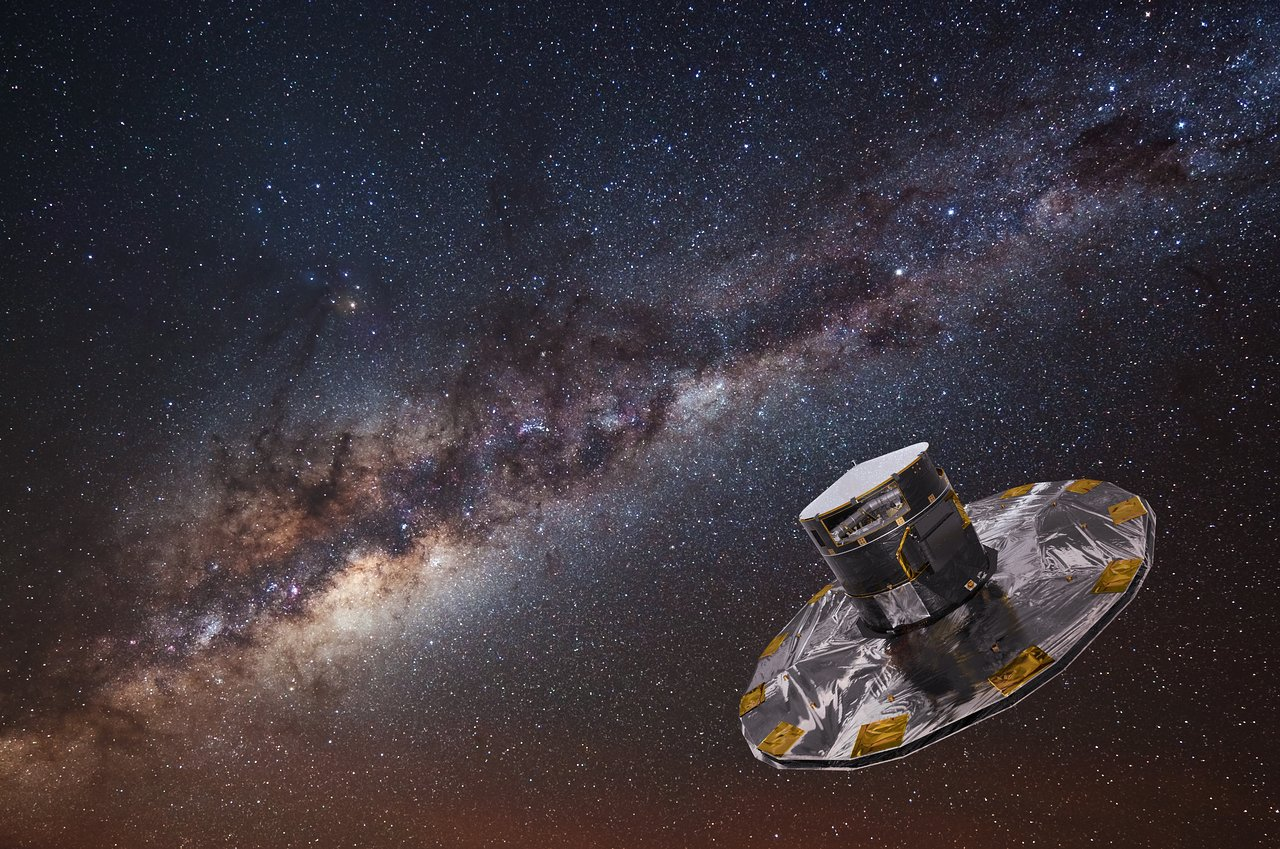

GAIA je svemirska astrometrijska misija Evropske svemirske agencije (ESA), čiji je osnovni cilj precizno merenje položaja i kretanja velikog broja astronomskih objekata. Lansirana je 19. decembra 2013. godine, a naučna posmatranja završena su 15. januara 2025. godine. Njeni podaci nastavljaju da se koriste za proučavanje strukture, kinematike i evolucije Mlečnog puta. Za razliku od teleskopa koji su prvenstveno usmereni na detaljno proučavanje pojedinačnih objekata, GAIA je osmišljena da sistematski posmatra veliki deo neba i stvori izuzetno obiman katalog astronomskih izvora.
Misija je omogućila da se proučavanje Galaksije pomeri sa zaključivanja na osnovu malog broja objekata na statističku analizu miliona i milijardi izvora.
Među najvažnijim rezultatima misije nalaze se:
- precizna merenja položaja zvezda na nebu;
- paralakse, na osnovu kojih možemo procenjivati udaljenosti;
- sopstvena kretanja zvezda po nebeskoj sferi;
- fotometrijska merenja u različitim opsezima talasnih dužina;
- radijalne brzine za deo posmatranih izvora;
- podaci o velikom broju dvojnih zvezda, promenljivih zvezda, jata i drugih astronomskih objekata.

Objavljivanje podataka odvijalo se u nekoliko izdanja. GAIA Data Release 3 (DR3) obuhvata približno 1,8 milijardi izvora, mada količina dostupnih podataka zavisi od vrste merenja i izabranog uzorka.

Podaci koje možemo da nađemo u katalogu su sledeći:

- _source_id_	- jedinstveni identifikator izvora u izdanju kataloga 
- _ra, dec_ - rektascenzija i deklinacija
- _l, b_ -	galaktička dužina i širina
- _parallax_ - paralaksa, u mililučnim sekundama (mas)
- _parallax_error_ - procena greške paralakse
- _pmra, pmdec_ - sopstvena kretanja u pravcu rektascenzije i deklinacije
- _phot_g_mean_mag_ - srednja prividna magnituda u GAIA \(G\) opsegu
- _bp_rp_ - indeks boje, razlika magnituda \(G_{\rm BP}-G_{\rm RP}\)
- _radial_velocity_ - radijalna brzina, dostupna samo za deo izvora

Ako želimo da preuzemo podatke, možemo da odemo na njihovu internet stranicu: https://www.cosmos.esa.int/web/gaia/data-release-3# gde možemo da koristimo _basic_ ili _advanced search_, u zavisnosti od toga šta nam je potrebno. Takođe, možemo direktno iz Python-a da komuniciramo sa bazom podataka, ali je za to neophodno da instaliramo __astroquery__ Python bibiloteku.

### <font color='yellow'>Ideja vežbe: Preuzimanje podataka iz različitih kataloga - za O zvezde iz GAIA DR3 kataloga, a za otvorena i globularna jata sa Vizier-a, i analiza datih podataka.</font>

#### <font color='red'>Na kraju svakog koraka, kada odradite ono što je bilo pitanje potrebno je iskomentarisati rešenje!</font>

Molim vas da ovu ćeliju koristite za sve biblioteke koje ćete naknadno da uvezete:

In [10]:
from astroquery.gaia import Gaia
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt
from astroquery.vizier import Vizier
import astropy.units as u
from astropy.coordinates import Angle

Sada hoćemo da nađemo podatke za zvezde tipa O i sačuvamo u dva odvojena fajla njihove rektascenzije, deklinacije i paralakse.

In [11]:
# zvezde spektralnog tipa O (Teff >= 30,000 K)
# uzimamo samo 2000

o_query = """
SELECT TOP 3000
    g.source_id, 
    g.ra, 
    g.dec, 
    g.parallax, 
    g.parallax_over_error, 
    g.pmra, 
    g.pmdec, 
    g.phot_g_mean_mag, 
    g.bp_rp,
    a.teff_gspphot
FROM gaiadr3.gaia_source AS g
JOIN gaiadr3.astrophysical_parameters AS a ON g.source_id = a.source_id
WHERE a.teff_gspphot >= 30000
  AND g.parallax > 0
  AND g.parallax_over_error > 5
"""

job_o = Gaia.launch_job_async(o_query)
df_o = job_o.get_results().to_pandas()
df_o.to_csv("o_stars.csv", index=False)

INFO: Query finished. [astroquery.utils.tap.core]


In [5]:
# učitavam podatke za O: ra, dec i parallax
df_o = pd.read_csv("o_stars.csv")
o_data = df_o[["ra", "dec", "parallax"]]

Sada preuzimamo podatke za otvorena jata: Optically visible open clusters and Candidates (Dias+ 2002-2015)

https://vizier.cds.unistra.fr/viz-bin/VizieR-3?-source=B/ocl/clusters

In [25]:
# učitavamo celi katalog - Vizier ima svoj row limit
Vizier.ROW_LIMIT = -1

# globularna jata
globular_result = Vizier.get_catalogs("VII/202")
df_globular = globular_result[0].to_pandas()

# zadržavam samo podatke koji su mi potrebni
df_globular_clean = df_globular[["ID", "RAJ2000", "DEJ2000"]]
df_globular_clean.to_csv("globular_clusters_harris.csv", index=False)

# otvorena jata
open_result = Vizier.get_catalogs("B/ocl")
df_open = open_result[0].to_pandas()

# zadržavam samo podatke koji su mi potrebni
df_open_clean = df_open[["RAJ2000", "DEJ2000", "Dist"]]
df_open_clean.to_csv("open_clusters_dias.csv", index=False)

##### <font color="green">1.  Prikazati grafik DEC od RA, pri čemu razlicitim simbolima oznaciti otvorena zvezdana jata i O zvezde.</font>

#### <font color="green">2. Odrediti udaljenosti do O zvezda. (Hint: Obratiti pažnju u kojoj jedinici je data paralaksa.)</font>

#### <font color="green">3. Određivanje položaja severnog galaktičkog pola</font>

Fitovati podatke funkcijom (zajedno podatke za O zvezde i otvorena jata) koja predstavlja veliki krug na nebeskoj sferi:

$$ \tan(\mathrm{\delta}) = \sin(\mathrm{\alpha}-\mathrm{\alpha}_{\omega})\tan(i), $$

gde su parametri fita $\mathrm{\alpha}_{\omega}$ i $i$.

Položaj severnog galaktičkog pola određuje se pomoću relacija:

$$ \mathrm{\alpha}_{\mathrm{PNG}} = \mathrm{\alpha}_{\omega} - 6\,\mathrm{h},$$

$$ \mathrm{\delta}_{\mathrm{PNG}} = 90^\circ - i.$$

Na osnovu dobijenih parametara fita odrediti koordinate severnog galaktičkog pola.

Dobijene vrednosti uporediti sa usvojenim vrednostima za epohu J2000:

$$ i = 62.87^\circ,
\qquad \mathrm{\alpha}_{\omega} = 18^\mathrm{h}51^\mathrm{m}26^\mathrm{s}.$$

Na grafiku prikazati posmatrane podatke i teorijsku funkciju velikog kruga nebeske sfere, definisanu jednačinom iznad.


#### <font color="green">4. Izračunati galaktičke koordinate l i b za globularna jata. (Možete npr. koristiti funkciju SkyCoord.)</font>

#### <font color="green">5. Galaktička latituda centra prividne raspodele.</font>
Odrediti galaktičku latitudu centra prividne raspodele globularnih jata. Kreirati prvo zone (pojase) jednakih površina na nebeskoj sferi, njih 10. Površina omotača jednog pojasa je  $2\pi h$, kako je $R=1$ za nebesku sferu. Kako nas zanima da izdelimo nebesku sferu na 10 zona, da je površina jednog omotača zapravo deseti deo površine cele nebeske sfere =>  $2\pi h=0.4\pi$, pa je visina $h = 0.2$, odnosno kako koristimo galaktički koordinatni sistem, prva zona od galaktičkog ekvatora $(b = 0)$ ide do $b = arcsin(0.2)$, kako je $R = 1$, a $sin(b) = h$ (vertikalna visina u odnosu na galaktički ekvator). Za granice zona imamo $b_j = arcsin(0.2(j-6))$, $j = 1, 2, 3, ..., 10$. Na sličan način se mogu naći galaktičke latitude koje odgovaraju centru pojasa, $b_{jc} = arcsin(0.2(j-6) + 0.1)$, $j = 1, 2, 3, ..., 10$. Zapravo, pravi se histogram po b, odnosno broje se objekti u konkretnim zonama. Grafički predstaviti histogram po galaktičkoj latitudi. Galaktička latituda maksimuma raspodele se može naći kao srednja vrednost tako grupisanih posmatranja:
$$b_{max} = \frac{\sum n_ib_i}{\sum n_i},$$
gde je $n_i$ broj zvezda u zoni čija je centralna galaktička latituda $b_i$. Proceniti  $b_{max}$ i za podelu od 20 zona. Koliko očekujemo da je  $b_{max}$, a kolika je računata vrednost?

#### <font color="green">6. Galaktička longituda centra prividne raspodele, slično kao prethodno.</font>

#### <font color="green">7. Ako pretpostavimo da je centar prividne raspodele globularnih jata upravo centar naše galaksije, kolike su onda l i b galaktičkog centra (koliko očekujemo i koje vrednosti su izračunate)? Kolike su onda RA i DEC za J2000, središta naše galaksije (uporediti sa koordinatama Sag A*).</font>